# 01 — EDA PaySim

Tujuan notebook ini adalah memverifikasi asumsi desain sebelum membangun pipeline, bukan membuat model.

| # | Pertanyaan | Keputusan yang bergantung padanya |
|---|---|---|
| 1 | Apakah `nameOrig` hampir selalu unik? | Apakah fitur riwayat pengirim berguna |
| 2 | Bagaimana tingkat fraud dan nominal fraud per tipe transaksi? | Ambang mode *scoring mati* |
| 3 | Apakah jumlah transaksi per `step` merata? | **Titik potong train/validasi/test** |
| 4 | Apakah TRANSFER dan CASH_OUT fraud saling terhubung? | Fitur akun penampung |
| 5 | Apakah kolom saldo membocorkan label? | Fitur mana yang boleh dipakai |

Di setiap bagian ada kotak **🧠 Keputusanmu**. Isi dulu sebelum lanjut.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..').resolve() / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fraud.decision import break_even_amount, FALSE_POSITIVE_COST

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
RAW = pathlib.Path('../data/raw/paysim.csv')
PARQUET = pathlib.Path('../data/processed/paysim.parquet')

## 0. Muat data
CSV PaySim berisi sekitar 6,3 juta baris. Tipe data diperkecil (`float32`, `category`) agar hemat RAM, lalu disimpan sebagai parquet supaya pembacaan berikutnya cepat.

In [2]:
dtypes = {
    'step': 'int16', 'type': 'category', 'amount': 'float64',
    'nameOrig': 'string', 'nameDest': 'string',
    'oldbalanceOrg': 'float64', 'newbalanceOrig': 'float64',
    'oldbalanceDest': 'float64', 'newbalanceDest': 'float64',
    'isFraud': 'int8', 'isFlaggedFraud': 'int8',
}
if PARQUET.exists():
    df = pd.read_parquet(PARQUET)
else:
    df = pd.read_csv(RAW, dtype=dtypes)
    PARQUET.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(PARQUET, index=False)

print(df.shape)
print(f"Memori: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()

(6362620, 11)
Memori: 0.52 GB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


In [3]:
print('Nilai kosong per kolom:'); print(df.isna().sum()[lambda s: s > 0])
print(f"\nTingkat fraud keseluruhan: {df.isFraud.mean():.4%}  ({df.isFraud.sum():,} kasus)")
print(f"Rentang step: {df.step.min()} – {df.step.max()} (1 step = 1 jam)")

Nilai kosong per kolom:
Series([], dtype: int64)

Tingkat fraud keseluruhan: 0.1291%  (8,213 kasus)
Rentang step: 1 – 743 (1 step = 1 jam)


## 1. Keunikan akun

In [14]:
orig_ratio = df.nameOrig.nunique() / len(df)
dest_ratio = df.nameDest.nunique() / len(df)
print(f"nameOrig unik / baris : {orig_ratio:.4f}")
print(f"nameDest unik / baris : {dest_ratio:.4f}")

orig_counts = df.nameOrig.value_counts()
print('\nDistribusi jumlah transaksi per pengirim:')
print(orig_counts.value_counts().sort_index().head(10))

print('\nAwalan nameDest (C = customer, M = merchant) per tipe:')
print(pd.crosstab(df.type, df.nameDest.str[0]))

nameOrig unik / baris : 0.9985
nameDest unik / baris : 0.4279

Distribusi jumlah transaksi per pengirim:
count
1    6344009
2       9283
3         15
Name: count, dtype: int64[pyarrow]

Awalan nameDest (C = customer, M = merchant) per tipe:
nameDest        C        M
type                      
CASH_IN   1399284        0
CASH_OUT  2237500        0
DEBIT       41432        0
PAYMENT         0  2151495
TRANSFER   532909        0


> **🧠 Keputusanmu:** Jika `nameOrig` hampir 100% unik, fitur seperti "rata-rata nominal pengirim 24 jam terakhir" hampir selalu kosong. Apakah fitur pengirim tetap dibangun (karena data nyata seperti IEEE-CIS punya riwayat), atau fokus ke fitur penerima untuk PaySim?
>
> _Jawaban:_
> nameOrig hampir 100% unik. mungkin fokus ke fitur penerima karena pengirim yg sama cuma sedikit.

## 2. Fraud per tipe transaksi dan ambang *scoring mati*

In [5]:
by_type = df.groupby('type', observed=True).agg(
    n=('isFraud', 'size'),
    fraud=('isFraud', 'sum'),
    fraud_rate=('isFraud', 'mean'),
)
fraud_amt = df[df.isFraud == 1].groupby('type', observed=True).amount.agg(['mean', 'median', 'max'])
by_type = by_type.join(fraud_amt.add_prefix('fraud_amt_'))
by_type['break_even_rp'] = by_type.fraud_rate.apply(break_even_amount)
by_type

,n,fraud,fraud_rate,fraud_amt_mean,fraud_amt_median,fraud_amt_max,break_even_rp
type,,,,,,,
CASH_IN,1399284,0,0.0000,NaN,NaN,NaN,inf
CASH_OUT,2237500,4116,0.0018,"1,455,102.5860","435,516.9050","10,000,000.0000","108,522,060.2527"
DEBIT,41432,0,0.0000,NaN,NaN,NaN,inf
PAYMENT,2151495,0,0.0000,NaN,NaN,NaN,inf
TRANSFER,532909,4097,0.0077,"1,480,891.6729","445,705.7600","10,000,000.0000","25,814,596.0459"


In [6]:
# Nominal fraud mentok di 10 juta? (simulator PaySim membagi transfer besar)
f = df[df.isFraud == 1]
print(f"Fraud dengan amount == 10.000.000: {(f.amount == 10_000_000).mean():.2%}")
print(f"isFlaggedFraud=1 total: {df.isFlaggedFraud.sum()}  (aturan bawaan PaySim)")

Fraud dengan amount == 10.000.000: 3.49%
isFlaggedFraud=1 total: 16  (aturan bawaan PaySim)


In [15]:
tc = df[df.type.isin(['TRANSFER', 'CASH_OUT'])]
tc = tc.assign(kuras=(tc.amount - tc.oldbalanceOrg).abs() < 0.01)  # nominal = saldo awal

hasil = tc.groupby(['type', 'kuras'], observed=True).isFraud.agg(
    tingkat_fraud='mean', jumlah='size', fraud='sum'
)
hasil['ambang_rp'] = hasil.tingkat_fraud.apply(break_even_amount)
hasil

tingkat_fraud   jumlah  fraud           ambang_rp
type     kuras                                                   
CASH_OUT False         0.0000  2233409     25 17,867,072,000.0000
         True          1.0000     4091   4091              0.0000
TRANSFER False         0.0003   528966    154    686,768,831.1688
         True          1.0000     3943   3943              0.0000

> **🧠 Keputusanmu:** Bandingkan `break_even_rp` dengan perkiraan sebelumnya (TRANSFER > Rp 26 juta, CASH_OUT > Rp 110 juta). Jika nominal fraud mentok di 10 juta, berapa banyak fraud yang benar-benar akan tertangkap oleh ambang ini? Apakah aturan *scoring mati* masih masuk akal?
>
> _Jawaban:_
> aku tidak bisa membaca hasilnya

## 3. Distribusi waktu — dasar untuk memotong data

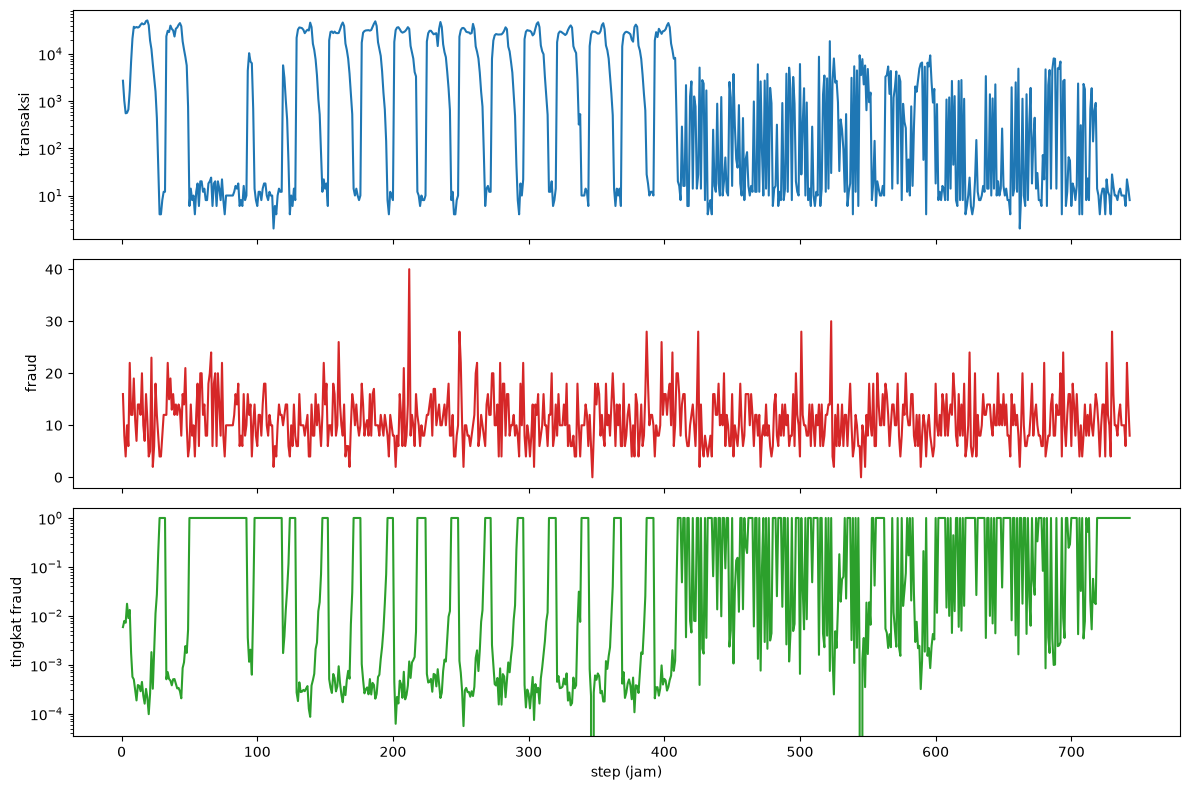

In [7]:
per_step = df.groupby('step').agg(n=('isFraud', 'size'), fraud=('isFraud', 'sum'))
per_step['fraud_rate'] = per_step.fraud / per_step.n

fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
ax[0].plot(per_step.index, per_step.n); ax[0].set_ylabel('transaksi'); ax[0].set_yscale('log')
ax[1].plot(per_step.index, per_step.fraud, color='C3'); ax[1].set_ylabel('fraud')
ax[2].plot(per_step.index, per_step.fraud_rate, color='C2'); ax[2].set_ylabel('tingkat fraud'); ax[2].set_yscale('log')
ax[2].set_xlabel('step (jam)')
plt.tight_layout(); plt.show()

In [8]:
cum = per_step.n.cumsum() / per_step.n.sum()
for q in [0.6, 0.7, 0.8, 0.9]:
    s = int((cum >= q).idxmax())
    print(f"{q:.0%} transaksi tercapai di step {s:>3} | fraud kumulatif: {per_step.fraud.loc[:s].sum() / per_step.fraud.sum():.1%}")

60% transaksi tercapai di step 281 | fraud kumulatif: 38.9%
70% transaksi tercapai di step 323 | fraud kumulatif: 44.4%
80% transaksi tercapai di step 355 | fraud kumulatif: 48.3%
90% transaksi tercapai di step 399 | fraud kumulatif: 54.3%


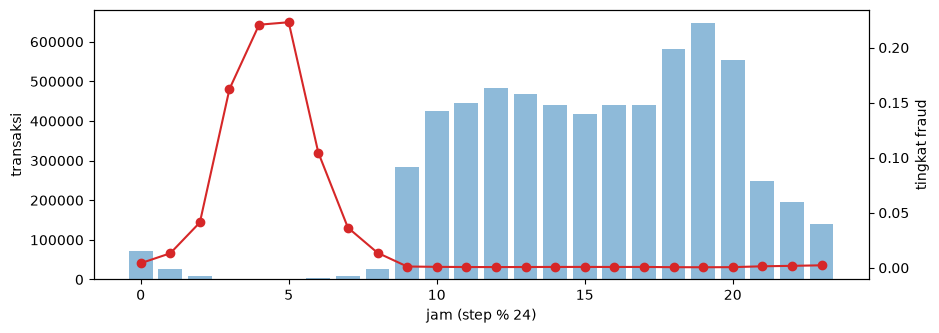

In [9]:
# Pola jam dalam sehari (step % 24)
hourly = df.assign(hour=df.step % 24).groupby('hour').agg(n=('isFraud', 'size'), fraud_rate=('isFraud', 'mean'))
fig, ax1 = plt.subplots(figsize=(10, 3.5))
ax1.bar(hourly.index, hourly.n, alpha=.5); ax1.set_ylabel('transaksi')
ax2 = ax1.twinx(); ax2.plot(hourly.index, hourly.fraud_rate, color='C3', marker='o'); ax2.set_ylabel('tingkat fraud')
ax1.set_xlabel('jam (step % 24)'); plt.show()

> **🧠 Keputusanmu (pertanyaan utama Fase 1):** Di step ke berapa data dipotong menjadi train / validasi / test?
> - Potong berdasarkan **step** atau berdasarkan **persentase jumlah baris**? Lihat grafik pertama: apakah keduanya menghasilkan hal yang sama?
> - Lihat grafik tingkat fraud. Jika bagian akhir data punya tingkat fraud yang jauh berbeda, apa dampaknya pada *precision* di test set dan pada keputusan BLOCK berbasis biaya?
> - Apakah `hour` boleh menjadi fitur? Apa risikonya jika polanya hanya artefak simulator?
>
> _Jawaban:_
> - sepertinya step lebih baik karena fraud ada di jam tertentu
> - mungkin precision akan lebih rendah di jam tertentu
> - jika hour jadi fitur ada kemungkinan di jam tertentu yg terdeteksi fraud lebih rendah

## 4. Apakah TRANSFER → CASH_OUT fraud saling terhubung?

In [10]:
ft = df[(df.isFraud == 1) & (df.type == 'TRANSFER')]
fc = df[(df.isFraud == 1) & (df.type == 'CASH_OUT')]

# (a) Penerima TRANSFER fraud muncul sebagai pengirim CASH_OUT fraud?
linked_by_account = ft.nameDest.isin(set(fc.nameOrig)).mean()
print(f"(a) Terhubung lewat akun (nameDest TRANSFER = nameOrig CASH_OUT): {linked_by_account:.2%}")

# (b) Terhubung lewat nominal yang sama pada step yang sama atau berdekatan?
m = ft[['step', 'amount']].merge(fc[['step', 'amount']], on='amount', suffixes=('_tf', '_co'))
m['gap'] = m.step_co - m.step_tf
m = m[m.gap.between(0, 24)]
print(f"(b) TRANSFER yang punya CASH_OUT nominal sama dalam ≤24 jam: {m.amount.nunique() / len(ft):.2%}")
print('Sebaran jarak waktu (jam):'); print(m.gap.value_counts().sort_index().head(6))

(a) Terhubung lewat akun (nameDest TRANSFER = nameOrig CASH_OUT): 0.00%
(b) TRANSFER yang punya CASH_OUT nominal sama dalam ≤24 jam: 95.97%
Sebaran jarak waktu (jam):
gap
0    4272
1      36
2      18
3      17
4      37
5      20
Name: count, dtype: int64


In [11]:
# Penerima yang menerima banyak transaksi (kandidat akun penampung)
dest_counts = df.nameDest.value_counts()
fraud_dest = df[df.isFraud == 1].nameDest
print('Jumlah transaksi masuk ke penerima fraud vs semua penerima:')
print(pd.DataFrame({
    'penerima_fraud': dest_counts.reindex(fraud_dest.unique()).describe(),
    'semua_penerima': dest_counts.describe(),
}))

Jumlah transaksi masuk ke penerima fraud vs semua penerima:
       penerima_fraud  semua_penerima
count      8,169.0000  2,722,362.0000
mean           8.0362          2.3372
std            9.8113          4.5493
min            1.0000          1.0000
25%            1.0000          1.0000
50%            4.0000          1.0000
75%           11.0000          1.0000
max           89.0000        113.0000


> **🧠 Keputusanmu:** Jika (a) hampir 0% tetapi (b) tinggi, artinya simulator menghubungkan kedua langkah lewat nominal, bukan lewat akun. Apakah fitur `recv:{akun}` di Redis masih berguna? Fitur apa yang bisa menangkap pola (b) secara real-time tanpa mengetahui label?
>
> _Jawaban:_
> a 0% jadi yg terhubung nominalnya. mungkin fitur jumlah transfer dan cash out yg sama

## 5. Kebocoran label di kolom saldo

In [12]:
d = df.assign(
    err_orig=df.oldbalanceOrg - df.amount - df.newbalanceOrig,
    err_dest=df.oldbalanceDest + df.amount - df.newbalanceDest,
    orig_zero_after=(df.newbalanceOrig == 0),
    dest_zero_both=(df.oldbalanceDest == 0) & (df.newbalanceDest == 0),
)
d = d[d.type.isin(['TRANSFER', 'CASH_OUT'])]
summary = d.groupby('isFraud')[['orig_zero_after', 'dest_zero_both']].mean()
summary['err_orig≈0'] = d.groupby('isFraud').err_orig.apply(lambda s: (s.abs() < 1).mean())
summary['err_dest≈0'] = d.groupby('isFraud').err_dest.apply(lambda s: (s.abs() < 1).mean())
summary

,orig_zero_after,dest_zero_both,err_orig≈0,err_dest≈0
isFraud,,,,
0,0.9010,0.0006,0.0990,0.9039
1,0.9805,0.4963,0.9945,0.4842


In [13]:
# Uji cepat: pohon kecil HANYA dengan kolom saldo. AUC mendekati 1 = curiga bocor.
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

cols = ['oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'amount']
cut = d.step.quantile(0.8)
tr, te = d[d.step <= cut], d[d.step > cut]
tree = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=0).fit(tr[cols], tr.isFraud)
print(f"AUC (kolom saldo saja, pohon kedalaman 4): {roc_auc_score(te.isFraud, tree.predict_proba(te[cols])[:, 1]):.4f}")

AUC (kolom saldo saja, pohon kedalaman 4): 0.9830


> **🧠 Keputusanmu:** `newbalanceOrig` dan `newbalanceDest` adalah saldo **setelah** transaksi. Di sistem nyata, apakah nilai ini tersedia pada saat transaksi perlu dinilai (sebelum disetujui)? Kolom mana yang kamu pertahankan, dan mana yang dibuang?
>
> _Jawaban:_
> newbalancedest dibuang karena saldo belum masuk dari pengirim tapi saldo pengirim sudah berkurang

## Ringkasan temuan
Isi setelah semua bagian selesai, lalu salin ke `docs/keputusan.md`.

- Keunikan akun:
- Ambang *scoring mati*:
- Titik potong train/validasi/test:
- Hubungan TRANSFER→CASH_OUT:
- Kolom yang dibuang karena bocor: